# Setup

In [1]:
!pip install pyAudioAnalysis

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 MB 44.2 MB/s  0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyAudioAnalysis: filename=pyaudioanalysis-0.3.14-py3-none-any.whl size=41264436 sha256=e8a637f46dd85d37d0ca5837386d21b6e88f03103b6ff5a83191de7bdb6520b3
  Stored in directory: /root/.cache/pip/wheels/ce/0d/14/1f886c60ca303d25c3f1e9deae5455d6f33ce232a16d1c3616
Successfully built pyAudioAnalysis


In [1]:
import pandas as pd
import pickle
from pyAudioAnalysis import ShortTermFeatures

In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')

Mounted at /content/drive


## Pré-Processamento

In [8]:
import joblib

dataset_pkl = '/content/drive/MyDrive/Mestrado/Matérias/IA Adersarial/ASVspoof/dataset_asvspoof_completo.pkl'
data = joblib.load(dataset_pkl)

# Verificar as chaves do dicionário
print("Chaves carregadas:", data.keys())

Chaves carregadas: dict_keys(['X_train', 'y_train', 'X_test', 'y_test'])


In [18]:
X_train_raw = data['X_train']
y_train = data['y_train']
X_test_raw = data['X_test']
y_test = data['y_test']

In [22]:
import os
import numpy as np
import librosa

def extract_st_features(signal, sr, win_samples, step_samples):
        F, _ = ShortTermFeatures.feature_extraction(signal, sr, win_samples, step_samples)
        return F

def compute_cmvn_per_segment(features):
    """
    Aplica CMVN (Cepstral/Feature Mean and Variance Normalization)
    de forma estritamente independente para CADA arquivo de áudio individual.
    Garante zero contaminação (data leakage) entre amostras de teste.

    features shape: (n_features, n_frames)
    """
    mean = np.mean(features, axis=1, keepdims=True)
    std = np.std(features, axis=1, keepdims=True)
    std[std == 0] = 1e-8  # Previne divisão por zero em trechos silenciosos
    return (features - mean) / std




def compute_deltas(features):
    """
    Calcula as derivadas temporais de 1ª ordem (Delta) e 2ª ordem (Delta-Delta)
    ao longo dos quadros temporais (eixo do tempo / axis=1).
    """
    delta1 = np.gradient(features, axis=1)
    delta2 = np.gradient(delta1, axis=1)
    return np.vstack((features, delta1, delta2))




def extract_pyaudioanalysis_features(X_raw, sr=16000, win_sec=0.020, step_sec=0.010, apply_cmvn=True, include_deltas=True):
    """
    Recebe os sinais brutos padronizados (N, max_samples) e extrai o tensor de características.

    Parâmetros:
    - X_raw: Numpy array dos sinais brutos truncados/preenchidos (ex: N x 80000 para 5s a 16kHz)
    - sr: Taxa de amostragem (16000 Hz)
    - win_sec: Tamanho da janela (20 ms = 0.020s)
    - step_sec: Salto da janela (10 ms = 0.010s)
    - apply_cmvn: Aplica CMVN por arquivo
    - include_deltas: Concatena Delta e Delta-Delta (34 -> 102 atributos)
    """
    win_samples = int(win_sec * sr)
    step_samples = int(step_sec * sr)


    features_list = []
    total_samples = len(X_raw)


    print(f"\n[pyAudioAnalysis] Extraindo características de {total_samples} sinais...")


    for idx, signal in enumerate(X_raw):
        signal = signal.astype(np.float64)


        #Extração de características com pyAudioAnalysis
        F = extract_st_features(signal, sr, win_samples, step_samples)


        # Normalização CMVN independente por áudio
        if apply_cmvn:
            F = compute_cmvn_per_segment(F)


        # Adição de dinâmicas temporais
        if include_deltas:
            F = compute_deltas(F)


        features_list.append(F)


        if (idx + 1) % 500 == 0 or (idx + 1) == total_samples:
            print(f"Progresso pyAudioAnalysis: {idx + 1}/{total_samples} concluídos.")


    return np.array(features_list)

In [23]:
#Pré-processamento: Extração com pyAudioAnalysis + CMVN + Deltas
X_train, y_train = extract_pyaudioanalysis_features(
    X_train_raw,
    sr=16000,
    win_sec=0.020,     # 20ms
    step_sec=0.010,    # 10ms
    apply_cmvn=True,   # CMVN isolado por áudio
    include_deltas=True # Matriz expandida
), y_train


X_test, y_test = extract_pyaudioanalysis_features(
    X_test_raw,
    sr=16000,
    win_sec=0.020,
    step_sec=0.010,
    apply_cmvn=True,
    include_deltas=True
), y_test


[pyAudioAnalysis] Extraindo características de 4128 sinais...
Progresso pyAudioAnalysis: 500/4128 concluídos.
Progresso pyAudioAnalysis: 1000/4128 concluídos.
Progresso pyAudioAnalysis: 1500/4128 concluídos.
Progresso pyAudioAnalysis: 2000/4128 concluídos.
Progresso pyAudioAnalysis: 2500/4128 concluídos.
Progresso pyAudioAnalysis: 3000/4128 concluídos.
Progresso pyAudioAnalysis: 3500/4128 concluídos.
Progresso pyAudioAnalysis: 4000/4128 concluídos.
Progresso pyAudioAnalysis: 4128/4128 concluídos.

[pyAudioAnalysis] Extraindo características de 1032 sinais...
Progresso pyAudioAnalysis: 500/1032 concluídos.
Progresso pyAudioAnalysis: 1000/1032 concluídos.
Progresso pyAudioAnalysis: 1032/1032 concluídos.


In [24]:
#Salvando dados com pré-processamento completo
import joblib

pasta_tensores = "./tensores_extraidos"
os.makedirs(pasta_tensores, exist_ok=True)
dataset_pre_processado = {
    "X_train": X_train,
    "y_train": y_train,
    "X_test": X_test,
    "y_test": y_test
}
joblib.dump(dataset_pre_processado, os.path.join(pasta_tensores, "dataset_asvspoof_pre_processado.pkl"), compress=3)

['./tensores_extraidos/dataset_asvspoof_pre_processado.pkl']

In [25]:
#Salvando no google drive

caminho_arquivo_pkl = "/content/drive/MyDrive/Mestrado/Matérias/IA Adersarial/ASVspoof/"
os.makedirs(caminho_arquivo_pkl, exist_ok=True)
caminho_final_pkl = os.path.join(caminho_arquivo_pkl, "dataset_asvspoof_pre_processado.pkl")
joblib.dump(dataset_pre_processado, caminho_final_pkl, compress=3)
print(f"Dados salvos em {caminho_final_pkl}")

Dados salvos em /content/drive/MyDrive/Mestrado/Matérias/IA Adersarial/ASVspoof/dataset_asvspoof_pre_processado.pkl


##EDA

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==============================================================================
# Funções de Análise Exploratória
# ==============================================================================
def run_exploratory_data_analysis(X, y, top_k=10):
    """
    Realiza a análise exploratória dos atributos de áudio obtidos.

    Parâmetros:
    - X: array numpy de formato (N_amostras, atributos, N_frames)
    - y: array numpy com os rótulos (0 = bonafide, 1 = spoof)
    - top_k: quantidade de atributos mais discriminantes para exibir
    """
    print("=================================================================")
    print("        INICIANDO ANÁLISE EXPLORATÓRIA DE ATRIBUTOS (EDA)        ")
    print("=================================================================")

    # A. Agregação Temporal: Média ao longo dos quadros (N, 102, 499) -> (N, 102)
    X_mean = np.mean(X, axis=2)

    X_bonafide = X_mean[y == 0]
    X_spoof = X_mean[y == 1]

    print(f"Total de amostras: {len(y)} | Legítimos (Bona Fide): {len(X_bonafide)} | Falsos (Spoof): {len(X_spoof)}")

    # B. Teste Estatístico de Welch (t-test) e Tamanho do Efeito (Cohen's d)
    t_stats, p_vals = stats.ttest_ind(X_bonafide, X_spoof, equal_var=False, axis=0)

    mean_bonafide = np.mean(X_bonafide, axis=0)
    mean_spoof = np.mean(X_spoof, axis=0)
    std_bonafide = np.std(X_bonafide, axis=0)
    std_spoof = np.std(X_spoof, axis=0)

    # Cohen's d = |média1 - média2| / std_combinado
    pooled_std = np.sqrt((std_bonafide**2 + std_spoof**2) / 2.0)
    cohen_d = np.abs(mean_bonafide - mean_spoof) / (pooled_std + 1e-8)

    # Montagem do DataFrame com os resultados
    df_eda = pd.DataFrame({
        'Feature_Index': np.arange(len(FEATURE_NAMES)),
        'Feature_Name': FEATURE_NAMES,
        'Mean_BonaFide': mean_bonafide,
        'Mean_Spoof': mean_spoof,
        't_statistic': t_stats,
        'p_value': p_vals,
        'Cohen_d': cohen_d
    })

    # Ordena pelos atributos com maior separabilidade (maior Cohen's d)
    df_sorted = df_eda.sort_values(by='Cohen_d', ascending=False).reset_index(drop=True)

    print(f"\n--- TOP {top_k} ATRIBUTOS MAIS DISCRIMINANTES (Maior Cohen's d) ---")
    print(df_sorted[['Feature_Name', 'Cohen_d', 'p_value', 'Mean_BonaFide', 'Mean_Spoof']].head(top_k).to_string(index=False))

    # C. Visualizações Gráficas
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))

    # Graph 1: Perfil Espectral Médio dos 34 Atributos Base
    axes[0, 0].plot(mean_bonafide[:34], label='Bona Fide (Real)', color='green', linewidth=2, marker='o', markersize=4)
    axes[0, 0].plot(mean_spoof[:34], label='Spoof (Falso)', color='red', linestyle='--', linewidth=2, marker='x', markersize=4)
    axes[0, 0].set_title("1. Perfil Médio dos 34 Atributos Base (CMVN)", fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel("Índice do Atributo Base")
    axes[0, 0].set_ylabel("Valor Médio Normalizado")
    axes[0, 0].legend()

    # Graph 2: Top K Atributos com Maior Separabilidade (Cohen's d)
    sns.barplot(data=df_sorted.head(top_k), x='Cohen_d', y='Feature_Name', ax=axes[0, 1], palette='viridis')
    axes[0, 1].set_title(f"2. Top {top_k} Atributos por Separabilidade (Cohen's d)", fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel("Tamanho do Efeito (Cohen's d)")
    axes[0, 1].set_ylabel("")

    # Graph 3: Boxplot do Atributo nº 1 mais discriminante
    top_1_idx = df_sorted.loc[0, 'Feature_Index']
    top_1_name = df_sorted.loc[0, 'Feature_Name']

    df_box = pd.DataFrame({
        'Classe': ['Bona Fide'] * len(X_bonafide) + ['Spoof'] * len(X_spoof),
        'Valor': np.concatenate([X_bonafide[:, top_1_idx], X_spoof[:, top_1_idx]])
    })
    sns.boxplot(data=df_box, x='Classe', y='Valor', ax=axes[1, 0], palette=['#2ecc71', '#e74c3c'], showfliers=False)
    axes[1, 0].set_title(f"3. Distribuição do Atributo Top 1:\n'{top_1_name}'", fontsize=12, fontweight='bold')

    # Graph 4: Heatmap da Diferença Espectral Absoluta ao Longo do Tempo (Atributos Base x Primeiros 100 Frames)
    diff_matrix = np.abs(np.mean(X[y == 0], axis=0) - np.mean(X[y == 1], axis=0))
    sns.heatmap(diff_matrix[:34, :100], ax=axes[1, 1], cmap='magma', cbar_kws={'label': '|Diferença Abosluta|'})
    axes[1, 1].set_title("4. Matriz de Diferença Temporal Médias (|Bona Fide - Spoof|)", fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel("Quadros Temporais (Primeiros 100 frames / ~1 seg)")
    axes[1, 1].set_ylabel("Atributos Base")

    plt.tight_layout()
    plt.show()

    return df_sorted

In [3]:
import joblib

dataset_pkl = '/content/drive/MyDrive/Mestrado/Matérias/IA Adersarial/ASVspoof/dataset_asvspoof_pre_processado.pkl'
data = joblib.load(dataset_pkl)

# Verificar as chaves do dicionário
print("Chaves carregadas:", data.keys())

Chaves carregadas: dict_keys(['X_train', 'y_train', 'X_test', 'y_test'])


In [4]:
X_train = data['X_train']
y_train = data['y_train']
X_test = data['X_test']
y_test = data['y_test']

        INICIANDO ANÁLISE EXPLORATÓRIA DE ATRIBUTOS (EDA)        
Total de amostras: 4128 | Legítimos (Bona Fide): 2064 | Falsos (Spoof): 2064

--- TOP 10 ATRIBUTOS MAIS DISCRIMINANTES (Maior Cohen's d) ---
                   Feature_Name  Cohen_d      p_value  Mean_BonaFide  Mean_Spoof
          MFCC 5 (Mean) (Delta) 0.677113 1.122718e-98      -0.001951    0.000028
Spectral Rolloff (Mean) (Delta) 0.517227 2.537933e-59      -0.000513   -0.001535
Spectral Entropy (Mean) (Delta) 0.455744 5.354125e-47      -0.000955   -0.001923
          MFCC 4 (Mean) (Delta) 0.452463 1.417622e-46      -0.002313   -0.001294
          MFCC 2 (Mean) (Delta) 0.435684 2.645779e-43      -0.003531   -0.002791
        Chroma 3 (Mean) (Delta) 0.430087 3.017403e-42      -0.000791   -0.001725
        Chroma 1 (Mean) (Delta) 0.415515 1.707279e-39      -0.000496   -0.001265
        Chroma 4 (Mean) (Delta) 0.394700 6.107224e-36      -0.000420   -0.001419
        Chroma 6 (Mean) (Delta) 0.340558 1.875154e-27      -0.00

/tmp/ipykernel_526/2443680767.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_sorted.head(top_k), x='Cohen_d', y='Feature_Name', ax=axes[0, 1], palette='viridis')
/tmp/ipykernel_526/2443680767.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_box, x='Classe', y='Valor', ax=axes[1, 0], palette=['#2ecc71', '#e74c3c'], showfliers=False)


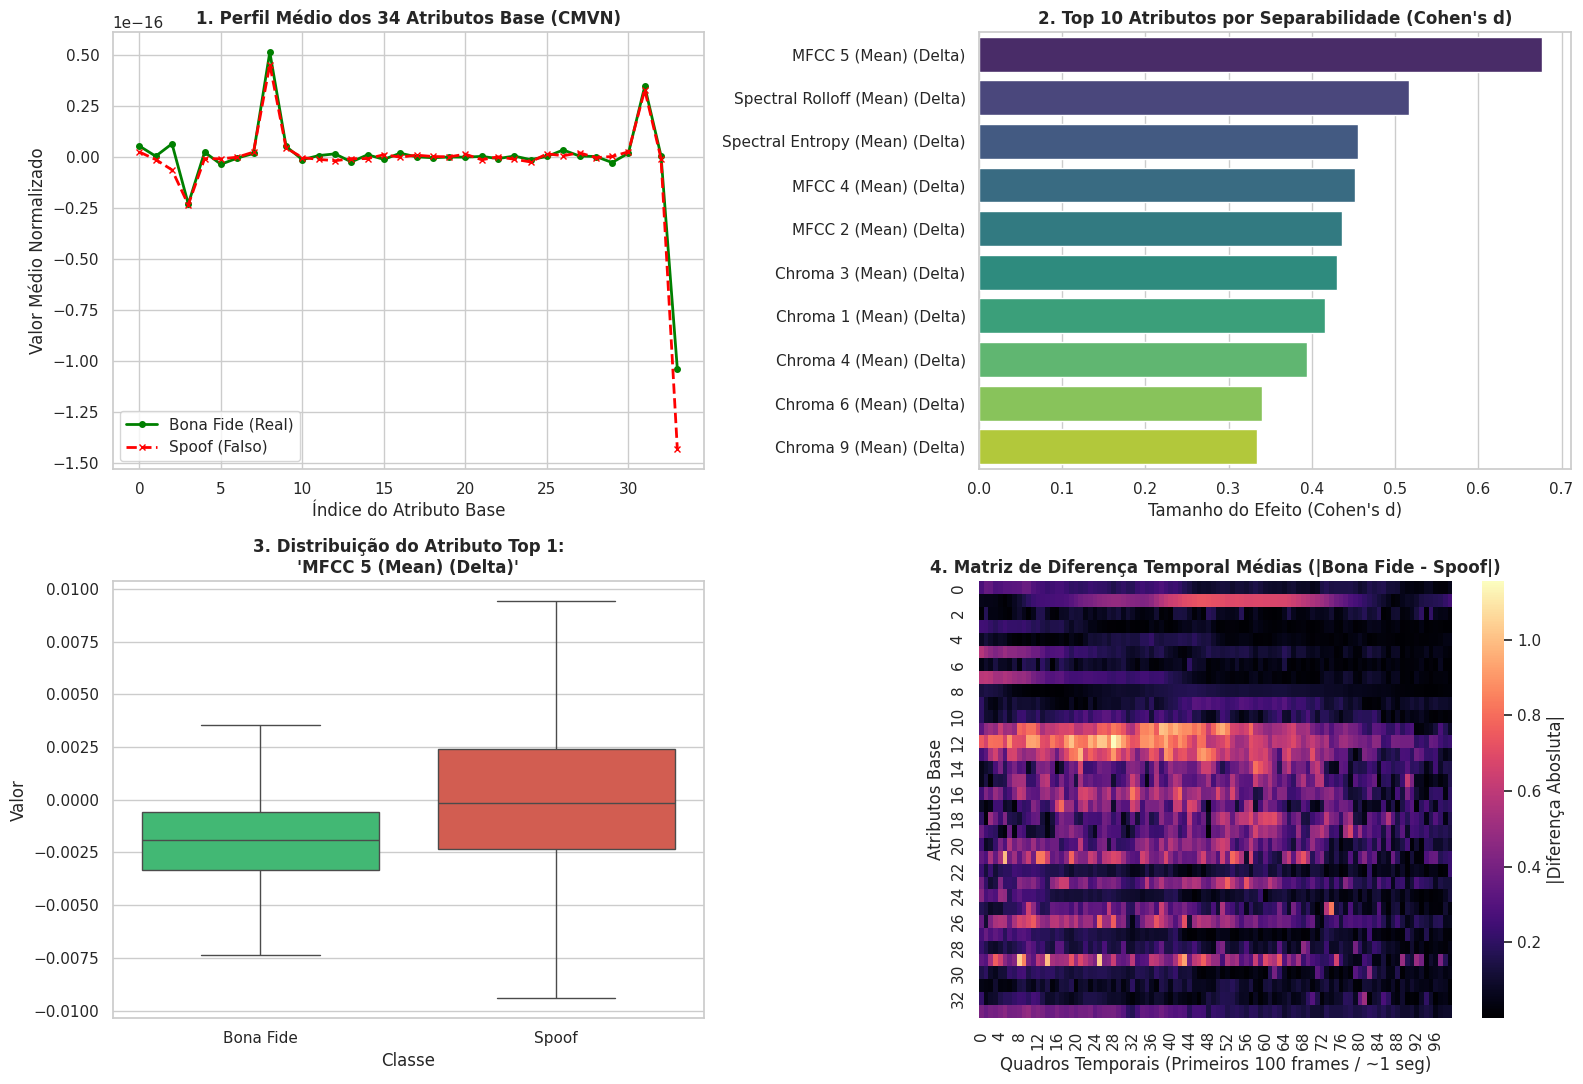

In [8]:
# Lista de nomes que o pyAudioAnalysis extrai (34 médias + 34 desvios padrões)
BASE_34 = [
    "Zero Crossing Rate", "Energy", "Entropy of Energy", "Spectral Centroid",
    "Spectral Spread", "Spectral Entropy", "Spectral Flux", "Spectral Rolloff"
] + [f"MFCC {i}" for i in range(1, 14)] \
  + [f"Chroma {i}" for i in range(1, 13)] \
  + ["Chroma Std"]

# Os 68 atributos base reais (34 médias + 34 desvios padrões de cada um)
BASE_68 = []
for name in BASE_34:
    BASE_68.append(f"{name} (Mean)")
for name in BASE_34:
    BASE_68.append(f"{name} (Std)")

# Expandindo para todos os atributos (68 base + 68 delta + 68 delta-delta)
FEATURE_NAMES = (
    [f"{name} (Base)" for name in BASE_68] +
    [f"{name} (Delta)" for name in BASE_68] +
    [f"{name} (Delta-Delta)" for name in BASE_68]
)

# Executar a análise exploratória agora com os 204 atributos mapeados corretamente
df_resultados_eda = run_exploratory_data_analysis(X_train, y_train, top_k=10)

## Treinamento do Modelo
### 1. LCNN
Código baseado no artigo da equipe T45:
Lavrentyeva, G., Novoselov, S., Tseren, A., Volkova, M., Gorlanov, A., & Kozlov, A. (2019).
STC Antispoofing Systems for the ASVspoof2019 Challenge. In Proc. INTERSPEECH 2019


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
from sklearn.metrics import roc_curve

In [8]:
# Detecta uso de GPU se disponível, caso contrário utiliza CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo de processamento selecionado: {device}")

Dispositivo de processamento selecionado: cpu


In [9]:
# ==============================================================================
# 1. Ativações Max-Feature-Map (MFM)
# ==============================================================================
class MFM2D(nn.Module):
    """
    Camada MFM para convoluções 2D.
    Reduz pela metade o número de canais de saída retendo os valores máximos canal a canal.
    """
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super(MFM2D, self).__init__()
        self.out_channels = out_channels
        # Gera o dobro de canais (2 * out_channels) para aplicar o max no meio
        self.conv = nn.Conv2d(in_channels, 2 * out_channels, kernel_size, stride, padding)

    def forward(self, x):
        x = self.conv(x)
        x1 = x[:, :self.out_channels, :, :]
        x2 = x[:, self.out_channels:, :, :]
        return torch.max(x1, x2)

class MFMLinear(nn.Module):
    """
    Camada MFM para camadas totalmente conectadas (Dense/Linear).
    """
    def __init__(self, in_features, out_features):
        super(MFMLinear, self).__init__()
        self.out_features = out_features
        self.fc = nn.Linear(in_features, 2 * out_features)

    def forward(self, x):
        x = self.fc(x)
        x1 = x[:, :self.out_features]
        x2 = x[:, self.out_features:]
        return torch.max(x1, x2)

# ==============================================================================
# 2. Arquitetura da Rede LCNN (Light CNN)
# ==============================================================================
class LCNN(nn.Module):
    def __init__(self, num_classes=2):
        super(LCNN, self).__init__()

        # Bloco Extrator de Características (Convoluções MFM + Max-Pooling)
        self.features = nn.Sequential(
            MFM2D(1, 32, kernel_size=5, stride=1, padding=2),
            nn.MaxPool2d(kernel_size=2, stride=2),

            MFM2D(32, 32, kernel_size=3, stride=1, padding=1),
            MFM2D(32, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(kernel_size=2, stride=2),

            MFM2D(32, 48, kernel_size=3, stride=1, padding=1),
            MFM2D(48, 48, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(48),
            nn.MaxPool2d(kernel_size=2, stride=2),

            MFM2D(48, 64, kernel_size=3, stride=1, padding=1),
            MFM2D(64, 32, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Camadas Densas / Classificador
        self.fc1 = MFMLinear(32 * 12 * 31, 160)
        self.dropout = nn.Dropout(p=0.7)
        self.fc2 = nn.Linear(160, num_classes)

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(1)

        x = self.features(x)
        x = x.view(x.size(0), -1)  # Achatamento
        x = self.fc1(x)
        x = self.dropout(x)
        out = self.fc2(x)
        return out

# ==============================================================================
# 3. Dataset e Métrica EER (Equal Error Rate)
# ==============================================================================
class AudioFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def compute_eer(y_true, y_scores):
    """Calcula a Equal Error Rate (EER) oficial do ASVspoof."""
    fpr, tpr, thresholds = roc_curve(y_true, y_scores, pos_label=1)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.absolute(fnr - fpr))
    eer = fpr[eer_idx]
    return eer * 100.0

# ==============================================================================
# 4. Pipeline de Treinamento e Validação
# ==============================================================================
def train_lcnn_model(X_train, y_train, X_test, y_test, epochs=15, batch_size=32, lr=0.0003):
    # Dataloaders
    train_dataset = AudioFeatureDataset(X_train, y_train)
    test_dataset = AudioFeatureDataset(X_test, y_test)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = LCNN(num_classes=2).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    print("\n================ INICIANDO TREINAMENTO DA LCNN ================")

    for epoch in range(1, epochs + 1):
        # --- Fase de Treino ---
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct_train += (preds == labels).sum().item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = (correct_train / total_train) * 100.0

        # --- Fase de Teste / Avaliação ---
        model.eval()
        test_loss = 0.0
        all_labels = []
        all_scores = []

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                test_loss += loss.item() * inputs.size(0)

                # Softmax para obter a probabilidade da classe Spoof
                probs = torch.softmax(outputs, dim=1)[:, 1]

                all_labels.extend(labels.cpu().numpy())
                all_scores.extend(probs.cpu().numpy())

        epoch_test_loss = test_loss / len(test_dataset)
        eer = compute_eer(np.array(all_labels), np.array(all_scores))

        scheduler.step(epoch_test_loss)

        print(f"Época [{epoch:02d}/{epochs:02d}] | "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
              f"Test Loss: {epoch_test_loss:.4f} | Test EER: {eer:.2f}%")

    print("===============================================================")
    return model

In [ ]:
# Treina a LCNN por 15 épocas
lcnn_trained = train_lcnn_model(
    X_train, y_train,
    X_test, y_test,
    epochs=15,
    batch_size=32,
    lr=0.0003
)


================ INICIANDO TREINAMENTO DA LCNN ================
Época [01/15] | Train Loss: 0.8854 | Train Acc: 73.59% | Test Loss: 0.8657 | Test EER: 15.70%
Época [02/15] | Train Loss: 0.5670 | Train Acc: 82.92% | Test Loss: 0.2943 | Test EER: 12.40%
Época [03/15] | Train Loss: 0.3762 | Train Acc: 87.67% | Test Loss: 0.2014 | Test EER: 7.75%
Época [04/15] | Train Loss: 0.2742 | Train Acc: 90.19% | Test Loss: 0.2746 | Test EER: 9.50%
Época [05/15] | Train Loss: 0.2011 | Train Acc: 92.66% | Test Loss: 0.5308 | Test EER: 9.30%
Época [06/15] | Train Loss: 0.1333 | Train Acc: 95.11% | Test Loss: 0.1568 | Test EER: 5.23%
Época [07/15] | Train Loss: 0.0874 | Train Acc: 97.09% | Test Loss: 0.1377 | Test EER: 4.84%
Época [08/15] | Train Loss: 0.0830 | Train Acc: 97.04% | Test Loss: 0.1170 | Test EER: 4.65%
Época [09/15] | Train Loss: 0.0582 | Train Acc: 97.65% | Test Loss: 0.1891 | Test EER: 3.29%
Época [10/15] | Train Loss: 0.0546 | Train Acc: 97.97% | Test Loss: 0.2231 | Test EER: 5.04%
Épo

In [ ]:
#Salvando o modelo
lcnn_path = '/content/drive/MyDrive/Mestrado/Matérias/IA Adersarial/ASVspoof/lcnn_asvspoof19.pth'
torch.save(lcnn_trained.state_dict(), lcnn_path)
print(f"Pesos do modelo LCNN salvos com sucesso no caminho {lcnn_path}")

### 2. XGBoost

In [10]:
import numpy as np
import xgboost as xgb
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

# ==============================================================================
# 1. Agregação Temporal
# ==============================================================================
def extract_summary_features(X_data):
    """
    Converte o tensor em um vetor plano calculando Média, Desvio Padrão,
    Mínimo e Máximo ao longo dos quadros temporais.
    """
    mean_feat = np.mean(X_data, axis=2)
    std_feat  = np.std(X_data, axis=2)
    min_feat  = np.min(X_data, axis=2)
    max_feat  = np.max(X_data, axis=2)

    # Concatena estatísticas
    X_flat = np.hstack([mean_feat, std_feat, min_feat, max_feat])
    return X_flat

# # ==============================================================================
# # 2. Métrica EER (Equal Error Rate)
# # ==============================================================================
# def compute_eer(y_true, y_scores):
#     """Calcula a Equal Error Rate (EER) oficial para comparação com a LCNN."""
#     fpr, tpr, thresholds = roc_curve(y_true, y_scores, pos_label=1)
#     fnr = 1 - tpr
#     eer_idx = np.nanargmin(np.absolute(fnr - fpr))
#     eer = fpr[eer_idx]
#     return eer * 100.0

# ==============================================================================
# 2. Treinamento e Avaliação do XGBoost
# ==============================================================================
def train_xgboost_baseline(X_train, y_train, X_test, y_test):
    print("--- Extraindo estatísticas temporais (Resumo 2D -> 1D) ---")
    X_train_flat = extract_summary_features(X_train)
    X_test_flat  = extract_summary_features(X_test)
    print(f"Formato final das características de treino: {X_train_flat.shape}")

    # Configuração do Classificador XGBoost
    model = xgb.XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    )

    print("\n--- Treinando o modelo XGBoost ---")
    model.fit(X_train_flat, y_train)

    # Predições no conjunto de teste
    y_pred  = model.predict(X_test_flat)
    y_probs = model.predict_proba(X_test_flat)[:, 1]  # Probabilidade da classe Spoof

    # Cálculo das métricas
    acc = accuracy_score(y_test, y_pred) * 100.0
    auc = roc_auc_score(y_test, y_probs)
    eer = compute_eer(y_test, y_probs)

    print("\n================ RESULTADOS XGBOOST (BASELINE) ================")
    print(f"Acurácia: {acc:.2f}%")
    print(f"ROC-AUC:  {auc:.4f}")
    print(f"EER:      {eer:.2f}%")
    print("===============================================================")

    return model, y_probs

In [11]:
xgb_model, xgb_probs = train_xgboost_baseline(X_train, y_train, X_test, y_test)

--- Extraindo estatísticas temporais (Resumo 2D -> 1D) ---
Formato final das características de treino: (4128, 816)

--- Treinando o modelo XGBoost ---

================ RESULTADOS XGBOOST (BASELINE) ================
Acurácia: 95.64%
ROC-AUC:  0.9926
EER:      4.46%


## Avaliação

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, det_curve, accuracy_score

def evaluate_model_performance(y_true, y_probs, model_name="Modelo", threshold=0.5):
    """
    Gera a Matriz de Confusão e a Curva DET de um classificador.

    Parâmetros:
    -----------
    y_true : array-like
        Rótulos reais (0 = Bona Fide / Real, 1 = Spoof / Falso).
    y_probs : array-like
        Probabilidades preditas do modelo para a classe positiva (1 / Spoof).
    model_name : str
        Nome do modelo para exibição nos títulos dos gráficos.
    threshold : float
        Limiar de decisão operacional (padrão: 0.5).
    """
    y_true = np.array(y_true)
    y_probs = np.array(y_probs)
    y_pred = (y_probs >= threshold).astype(int)

    # 1. Cálculo da Curva DET e da EER (Equal Error Rate)
    fpr, fnr, thresholds = det_curve(y_true, y_probs, pos_label=1)
    eer_idx = np.nanargmin(np.absolute(fnr - fpr))
    eer_val = fpr[eer_idx] * 100.0
    eer_thresh = thresholds[eer_idx] if eer_idx < len(thresholds) else threshold

    acc = accuracy_score(y_true, y_pred) * 100.0

    # 2. Configuração da Figura (2 painéis)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    class_names = ['Bona Fide\n(Real)', 'Spoof\n(Falso)']

    # --- PAINEL 1: Matriz de Confusão ---
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100.0

    # Rótulos com contagem e porcentagem
    labels = [f"{count}\n({norm:.1f}%)" for count, norm in zip(cm.flatten(), cm_norm.flatten())]
    labels = np.array(labels).reshape(2, 2)

    sns.heatmap(cm_norm, annot=labels, fmt="", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=axes[0], annot_kws={"size": 12, "weight": "bold"})

    axes[0].set_title(f"Matriz de Confusão — {model_name}\n(Acurácia: {acc:.2f}%)", fontsize=13, fontweight='bold')
    axes[0].set_xlabel("Classe Predita", fontsize=11)
    axes[0].set_ylabel("Classe Real", fontsize=11)

    # --- PAINEL 2: Curva DET (Decision Error Tradeoff) ---
    axes[1].plot(fpr * 100, fnr * 100, color='crimson', lw=2.5, label=f'Curva DET ({model_name})')
    axes[1].plot([0, 100], [0, 100], color='gray', linestyle='--', label='Linha de Referência')

    # Ponto EER
    axes[1].scatter(eer_val, eer_val, color='black', s=80, zorder=5,
                    label=f'EER = {eer_val:.2f}% (Threshold: {eer_thresh:.3f})')

    axes[1].set_title(f"Curva DET — {model_name}", fontsize=13, fontweight='bold')
    axes[1].set_xlabel("Taxa de Falsos Positivos / FPR (%)", fontsize=11)
    axes[1].set_ylabel("Taxa de falsos Negativos / FNR (%)", fontsize=11)
    axes[1].set_xlim([0, max(max(fpr*100), 50)])
    axes[1].set_ylim([0, max(max(fnr*100), 50)])
    axes[1].grid(True, linestyle=':', alpha=0.6)
    axes[1].legend(loc='upper right', fontsize=10)

    plt.tight_layout()
    plt.show()

    print(f"=== RELATÓRIO DE DESEMPENHO ({model_name}) ===")
    print(f"• Acurácia Global:      {acc:.2f}%")
    print(f"• Equal Error Rate (EER): {eer_val:.2f}% (no limiar {eer_thresh:.4f})")
    print("==============================================")

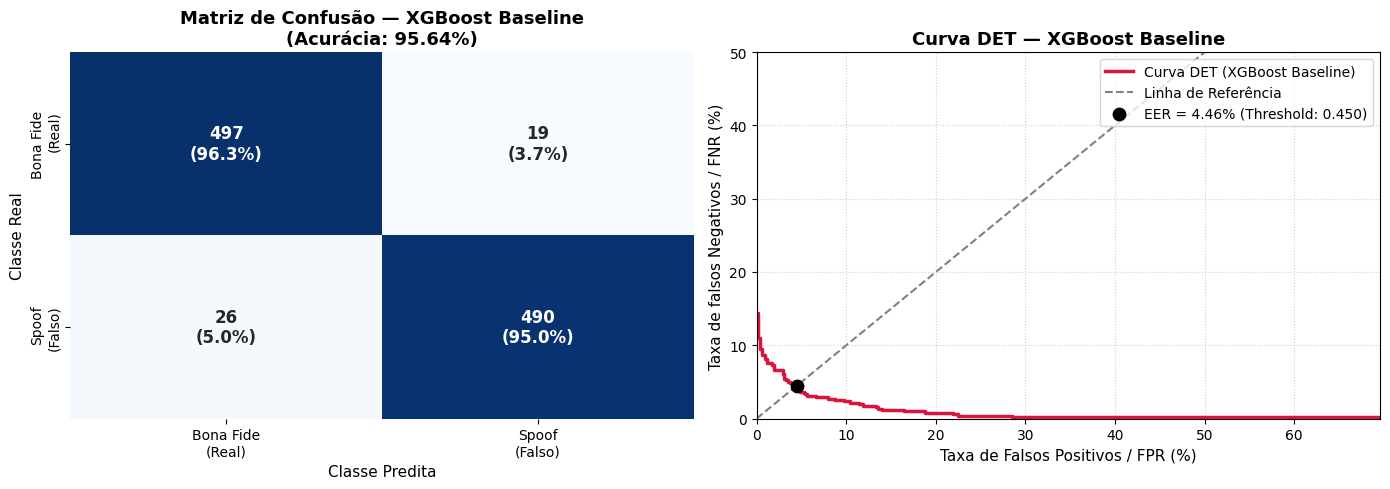

=== RELATÓRIO DE DESEMPENHO (XGBoost Baseline) ===
• Acurácia Global:      95.64%
• Equal Error Rate (EER): 4.46% (no limiar 0.4500)


In [14]:
evaluate_model_performance(y_test, xgb_probs, model_name="XGBoost Baseline")